# V-JEPA: predict masked spatio-temporal tubes of a video

[V-JEPA](https://arxiv.org/abs/2404.08471) ([code](https://github.com/facebookresearch/jepa)) applies feature prediction to video. Masks are tubes that span time, so the model cannot copy a target patch from a neighbouring frame. Two strategies run together: many small short-range blocks and a few large long-range ones. [V-JEPA 2](https://arxiv.org/abs/2506.09985) ([code](https://github.com/facebookresearch/vjepa2)) uses the same objective with 3D RoPE (`use_rope=True`), which we use here.

In [1]:
import torch

from torch_world import metrics, plots
from torch_world.envs import PointMass
from torch_world.masks import MultiBlock3DMask
from torch_world.models import VJEPA
from torch_world.nn import MaskedPredictor, VisionTransformer
from torch_world.utils import linear_schedule

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
FRAMES = 8

## Videos and tube masks
Every panel shows one tubelet (2 frames). A tube masks the same region at every time step.

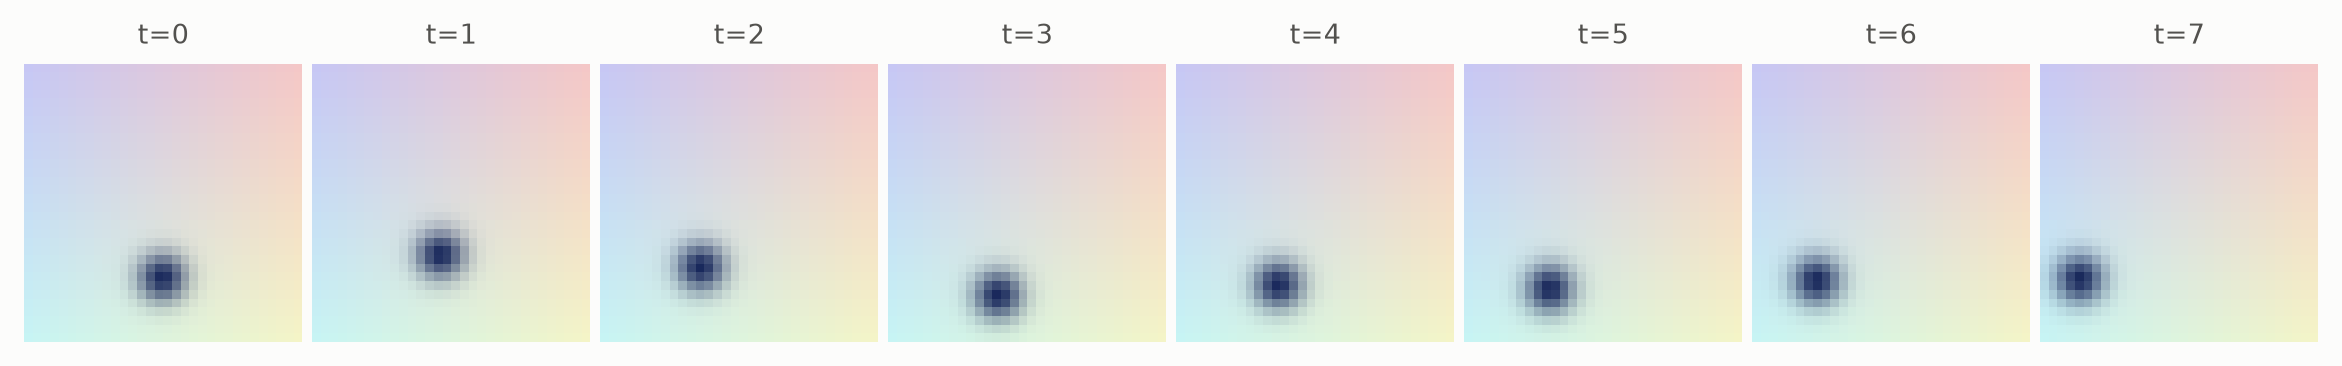

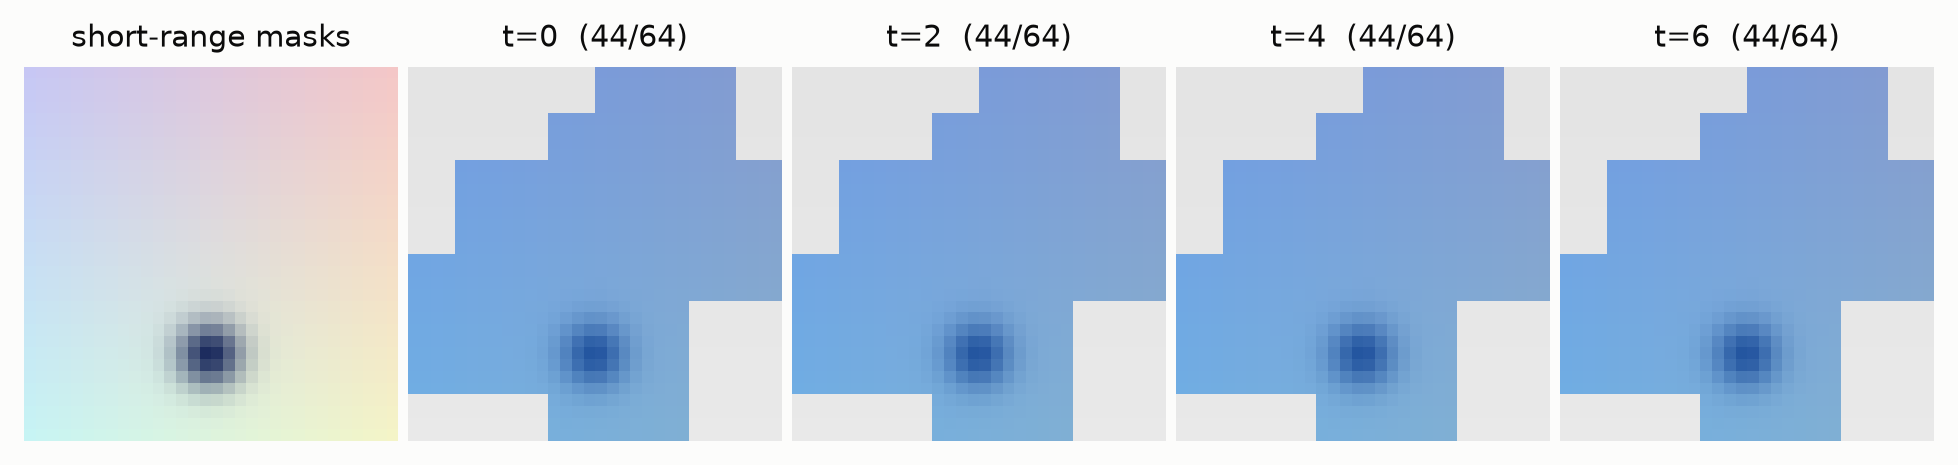

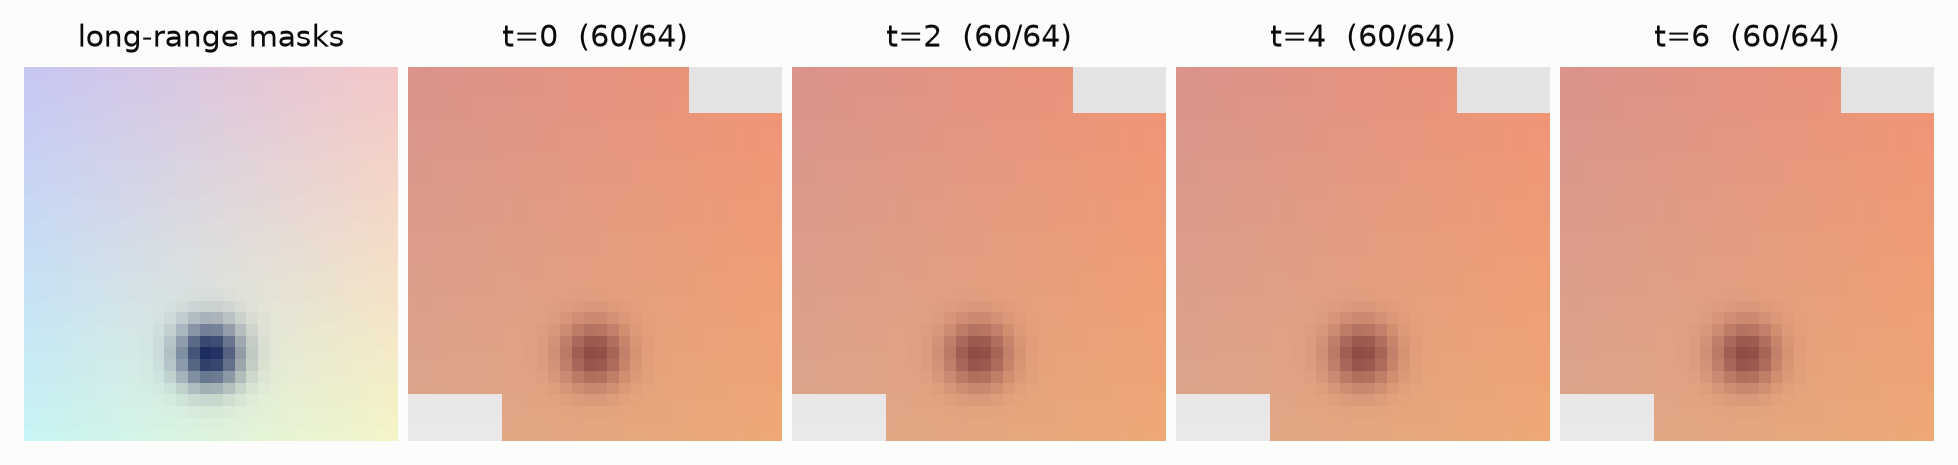

In [2]:
env = PointMass(batch_size=64, size=32, device=device)
video = env.collect(FRAMES)["pixels"]
display(plots.images(video[0], [f"t={t}" for t in range(FRAMES)]))

encoder = VisionTransformer(img_size=32, patch_size=4, embed_dim=192, depth=6, num_heads=6, num_frames=FRAMES, tubelet_size=2, use_rope=True)
maskers = [
    MultiBlock3DMask(encoder.grid, spatial_scale=(0.15, 0.15), num_blocks=8),
    MultiBlock3DMask(encoder.grid, spatial_scale=(0.7, 0.7), num_blocks=2),
]
T, H, W = encoder.grid
for name, masker in zip(["short-range", "long-range"], maskers):
    _, [pred] = masker(1)
    layers = {f"t={2 * t}": pred[0][(pred[0] >= t * H * W) & (pred[0] < (t + 1) * H * W)] - t * H * W for t in range(T)}
    display(plots.masks(video[0, 0], (H, W), layers, size=1.6, color=plots.SERIES[0 if name == "short-range" else 1], title=f"{name} masks"))

## Train

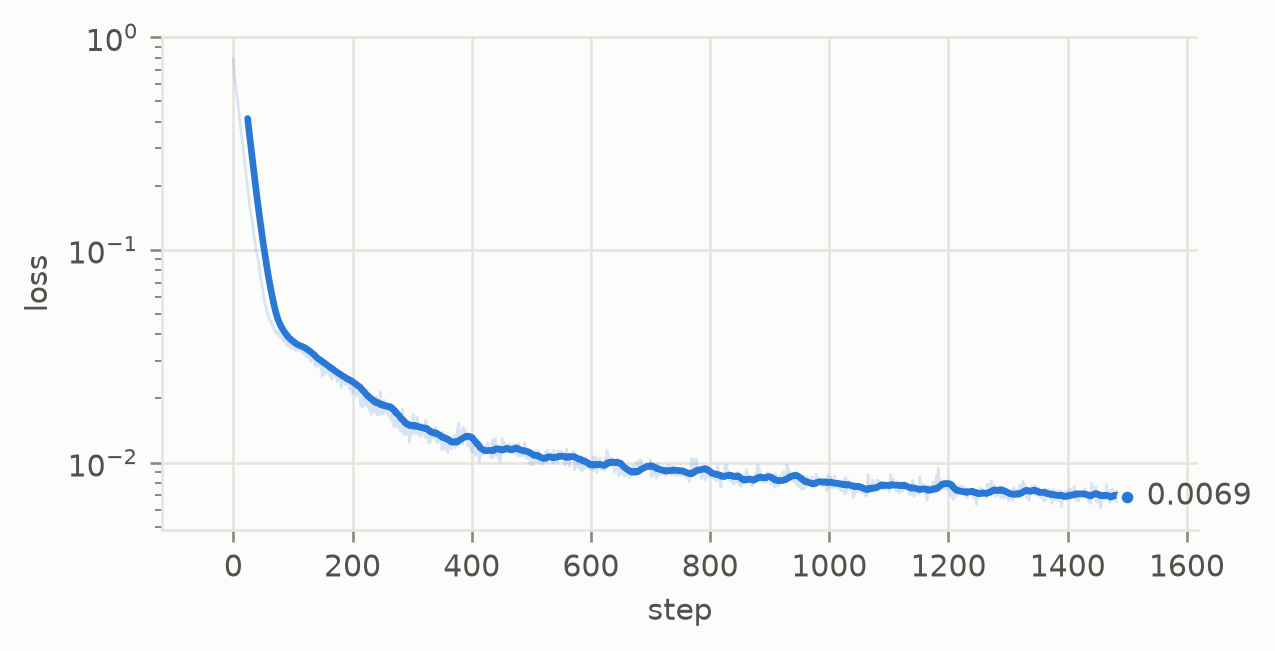

In [3]:
predictor = MaskedPredictor(encoder.grid, 192, 96, depth=4, num_heads=6, num_mask_tokens=2, zero_init_mask_tokens=True, use_rope=True)
model = VJEPA(encoder, predictor).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.04)

steps, log = 1500, {"L1": []}
for step in range(steps):
    videos = env.collect(FRAMES)["pixels"].transpose(1, 2)
    masks = [m(len(videos)) for m in maskers]
    masks_enc = [enc.to(device) for (enc,), _ in masks]
    masks_pred = [pred.to(device) for _, (pred,) in masks]
    loss = model(videos, masks_enc, masks_pred)["loss"]
    opt.zero_grad()
    loss.backward()
    opt.step()
    model.update_target(linear_schedule(0.998, 1.0, step, steps))
    log["L1"].append(loss.item())

plots.curves(log)

## What the features know
Video features should encode motion. Three metrics from the papers, on frozen features of 3072 fresh clips (2560 to fit, 512 to test), against the same encoder at random initialization:
- **attentive probe**, the evaluation of V-JEPA and V-JEPA 2: a learned query cross-attends to all frozen tokens and classifies the direction of motion into 8 sectors (chance is 12.5%);
- **linear probe**: regresses the displacement over the clip from mean-pooled features, scored by R²;
- **RankMe**: the effective rank of the pooled features, out of 192 dimensions, after removing their mean (`center=True`): the clips are mostly empty background, which every pooled feature shares.

In [4]:
clips = PointMass(batch_size=3072, size=32, device=device).collect(FRAMES, generator=torch.Generator().manual_seed(7))
displacement = clips["states"][:, -1] - clips["states"][:, 0]
direction = ((torch.atan2(displacement[:, 1], displacement[:, 0]) + torch.pi) / (2 * torch.pi) * 8).long() % 8

baseline = VisionTransformer(img_size=32, patch_size=4, embed_dim=192, depth=6, num_heads=6, num_frames=FRAMES, tubelet_size=2, use_rope=True).to(device)
print(f"{'':12s}{'attentive probe':>17s}{'linear probe R²':>17s}{'RankMe':>9s}")
for name, net in {"random init": baseline, "V-JEPA": model.target_encoder}.items():
    with torch.no_grad():
        tokens = torch.cat([net(c.transpose(1, 2)) for c in clips["pixels"].split(512)])
    attentive = metrics.attentive_probe(tokens[:2560], direction[:2560], tokens[2560:], direction[2560:], epochs=30, lr=3e-3, generator=torch.Generator().manual_seed(0))
    pooled = tokens.mean(1)
    linear = metrics.linear_probe(pooled[:2560], displacement[:2560], pooled[2560:], displacement[2560:])
    print(f"{name:12s}{attentive.score:17.1%}{linear.score:17.3f}{metrics.rankme(pooled, center=True):9.1f}")

              attentive probe  linear probe R²   RankMe


random init             30.1%            0.511     17.4


V-JEPA                  30.3%            0.548     13.8
